## **Bonds**

In [398]:
# Import of necessary packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as st
import json
import os

In [399]:
def params_to_json(prefix, mean, variance):
    """Adds descriptive statistics to json file"""
    json_path = "/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/relationships/statistics.json"
    params={}
    if os.path.exists(json_path):
        try:
            with open(json_path, "r") as f:
                params = json.load(f)
        except json.JSONDecodeError:
                pass
    params[f"{prefix}_mean"] = mean
    params[f"{prefix}_variance"] = variance
    with open(json_path, "w") as f:
        json.dump(params, f)

### **Czech Bonds**

In [400]:
# Load in the Data
cz_bond = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/bonds/bonds.xlsx", sheet_name="CZ")

# Convert Column Date to Date Format
cz_bond["Date"] = pd.to_datetime(cz_bond["Date"])

# Sort Data by Date
cz_bond.sort_values("Date", inplace=True)

# Reset Index
cz_bond.reset_index(inplace=True)
# Drop former index column
del cz_bond['index']

# Set end of 2024 as cut off point
cz_bond = cz_bond[cz_bond["Date"] <= "2024-12-31"]

In [401]:
# Extract the year from the 'date' column
cz_bond['Year'] = cz_bond['Date'].dt.year

# Create year-to-year log return 
cz_bond["Log_return"] = np.nan
for i in range(1,len(cz_bond)):
    cz_bond.loc[i, "Log_return"] = np.round(np.log(cz_bond.loc[i, "Trade Price"]/cz_bond.loc[i-1, "Trade Price"]), 4)

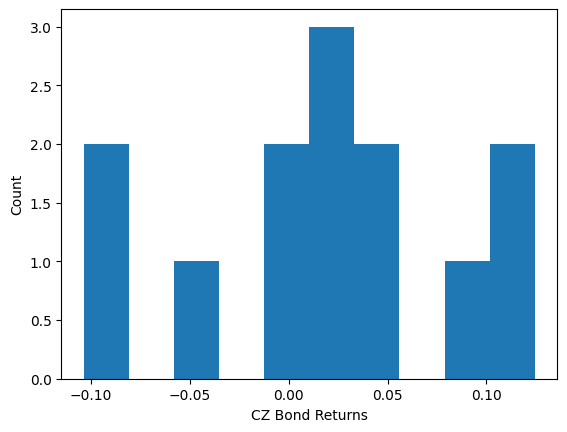

In [402]:
# Histogram
plt.hist(cz_bond["Log_return"])
plt.ylabel("Count")
plt.xlabel("CZ Bond Returns")
plt.savefig("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/Visualizations/Bonds/CZBond_hist.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [403]:
# Check for Outliers
# Calculate mean, std
cz_std = np.std(cz_bond["Log_return"])
cz_mean = np.mean(cz_bond["Log_return"])

# Calculate Z-Score
cz_bond["Z-Score"] = np.nan
for i in range(len(cz_bond)):
    cz_bond.loc[i, "Z-Score"] = ((cz_bond.loc[i, "Log_return"] - cz_mean) / cz_std)

# Print out Outliers
cz_bond[np.abs(cz_bond["Z-Score"])>=3] # Empty hence no outliers

,Date,Trade Price,Year,Log_return,Z-Score


In [404]:
# Display statistics
cz_mean = np.mean(cz_bond["Log_return"])
cz_var = np.var(cz_bond["Log_return"])
print(f"Czech bonds have mean {np.round(cz_mean, 4)} and variance {np.round(cz_var,4)}.")

Czech bonds have mean 0.0176 and variance 0.0047.


In [405]:
# Check for max and min return
cz_bond[cz_bond["Log_return"] == np.max((cz_bond["Log_return"]))], cz_bond[cz_bond["Log_return"] == np.min(cz_bond["Log_return"])]

(        Date  Trade Price  Year  Log_return   Z-Score
 1 2012-12-31     119.1358  2012      0.1244  1.561243,
          Date  Trade Price  Year  Log_return   Z-Score
 10 2021-12-31     124.7198  2021     -0.1037 -1.774411)

In [406]:
# Save Mean and Variance
params_to_json("CZBond", np.round(cz_mean,4), np.round(cz_var,4))

In [407]:
# Save Data
cz_bond.to_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/bonds/CZBonds10YR.xlsx", sheet_name="CZBond")

### **German Bonds**

In [408]:
# Load in the Data
de_bond = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/bonds/bonds.xlsx", sheet_name="DE")

# Convert Column Date to Date Format
de_bond["Date"] = pd.to_datetime(de_bond["Date"])

# Sort Data by Date
de_bond.sort_values("Date", inplace=True)

# Reset Index
de_bond.reset_index(inplace=True)
# Drop former index column
del de_bond['index']

# Set end of 2024 as cut off point
de_bond = de_bond[de_bond["Date"] <= "2024-12-31"]

In [409]:
# Extract the year from the 'date' column
de_bond['Year'] = de_bond['Date'].dt.year

# Create year-to-year log return 
de_bond["Log_return"] = np.nan
for i in range(1,len(de_bond)):
    de_bond.loc[i, "Log_return"] = np.round(np.log(de_bond.loc[i, "Trade Price"]/de_bond.loc[i-1, "Trade Price"]), 4)

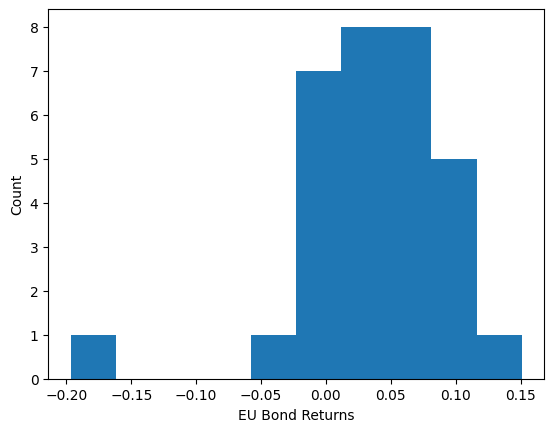

In [410]:
# Histogram
plt.hist(de_bond["Log_return"])
plt.ylabel("Count")
plt.xlabel("EU Bond Returns")
plt.savefig("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/Visualizations/Bonds/DEBond_hist.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [411]:
# Check for Outliers
# Calculate mean, std
de_std = np.std(de_bond["Log_return"])
de_mean = np.mean(de_bond["Log_return"])

# Calculate Z-Score
de_bond["Z-Score"] = np.nan
for i in range(len(de_bond)):
    de_bond.loc[i, "Z-Score"] = ((de_bond.loc[i, "Log_return"] - de_mean) / de_std)

# Print out Outliers
de_bond[np.abs(de_bond["Z-Score"])>=3] # Empty hence no outliers

,Date,Trade Price,Year,Log_return,Z-Score
29,2022-12-31,555.4977,2022,-0.1967,-3.822177


In [412]:
# Drop outliers
de_bond = de_bond[np.abs(de_bond["Z-Score"])<3]

In [413]:
# Display statistics
de_mean = np.mean(de_bond["Log_return"])
de_var = np.var(de_bond["Log_return"])
print(f"German bonds have mean {np.round(de_mean, 4)} and variance {np.round(de_var,4)}.")

German bonds have mean 0.0427 and variance 0.0019.


In [414]:
# Check for max and min return
de_bond[de_bond["Log_return"] == np.max((de_bond["Log_return"]))], de_bond[de_bond["Log_return"] == np.min(de_bond["Log_return"])]

(        Date  Trade Price  Year  Log_return   Z-Score
 2 1995-12-31     227.5302  1995      0.1508  1.909625,
          Date  Trade Price  Year  Log_return   Z-Score
 28 2021-12-31     676.2501  2021     -0.0273 -1.028026)

In [415]:
# Save Mean and Variance
params_to_json("DEBond", np.round(de_mean,4), np.round(de_var,4))

In [416]:
# Save Data
de_bond.to_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/bonds/DEBonds10YR.xlsx", sheet_name="DEbond")

### **American Bonds**

In [417]:
# Load in the Data
us_bond = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/bonds/bonds.xlsx", sheet_name="US")

# Convert Column Date to Date Format
us_bond["Date"] = pd.to_datetime(us_bond["Date"])

# Sort Data by Date
us_bond.sort_values("Date", inplace=True)

# Reset Index
us_bond.reset_index(inplace=True)
# Drop former index column
del us_bond['index']

# Set end of 2024 as cut off point
us_bond = us_bond[us_bond["Date"] <= "2024-12-31"]

In [418]:
# Extract the year from the 'date' column
us_bond['Year'] = us_bond['Date'].dt.year

# Create year-to-year log return 
us_bond["Log_return"] = np.nan
for i in range(1,len(us_bond)):
    us_bond.loc[i, "Log_return"] = np.round(np.log(us_bond.loc[i, "Trade Price"]/us_bond.loc[i-1, "Trade Price"]), 4)

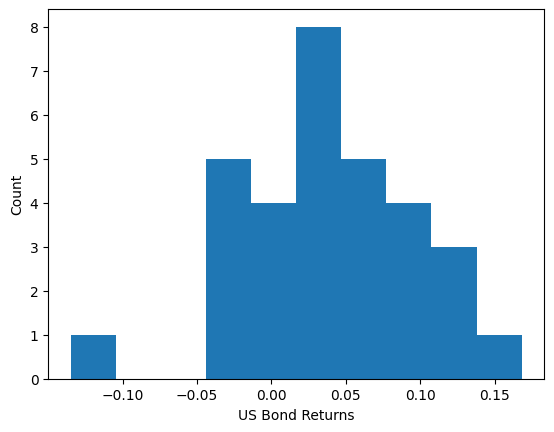

In [419]:
# Histogram
plt.hist(us_bond["Log_return"])
plt.ylabel("Count")
plt.xlabel("US Bond Returns")
plt.savefig("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/Visualizations/Bonds/USBond_hist.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [420]:
# Check for Outliers
# Calculate mean, std
us_std = np.std(us_bond["Log_return"])
us_mean = np.mean(us_bond["Log_return"])

# Calculate Z-Score
us_bond["Z-Score"] = np.nan
for i in range(len(us_bond)):
    us_bond.loc[i, "Z-Score"] = ((us_bond.loc[i, "Log_return"] - us_mean) / us_std)

# Print out Outliers
us_bond[np.abs(us_bond["Z-Score"])>=3] # Empty hence no outliers

,Date,Trade Price,Year,Log_return,Z-Score


In [421]:
# Drop outliers
us_bond = us_bond[np.abs(us_bond["Z-Score"])<3]

In [422]:
# Display statistics
us_mean = np.mean(us_bond["Log_return"])
us_var = np.var(us_bond["Log_return"])
print(f"German bonds have mean {np.round(us_mean, 4)} and variance {np.round(us_var,4)}.")

German bonds have mean 0.0384 and variance 0.0036.


In [423]:
# Check for max and min return
us_bond[us_bond["Log_return"] == np.max((us_bond["Log_return"]))], us_bond[us_bond["Log_return"] == np.min(us_bond["Log_return"])]

(        Date  Trade Price  Year  Log_return   Z-Score
 2 1995-12-31     296.9053  1995      0.1681  2.170327,
          Date  Trade Price  Year  Log_return   Z-Score
 29 2022-12-31      813.899  2022     -0.1348 -2.898736)

In [424]:
# Save Mean and Variance
params_to_json("USBond", np.round(us_mean,4), np.round(us_var,4))

In [425]:
# Save Data
us_bond.to_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/bonds/USBonds10YR.xlsx", sheet_name="USbond")